In [15]:
# FarsiLens AI v2
# Step 1: Check the Python environment

import sys
import os
import time
import platform

print("Project: FarsiLens AI")
print("Python version:", sys.version.split()[0])
print("Operating system:", platform.system())

if __import__("importlib").util.find_spec("torch"):
    import torch
    print("PyTorch version:", torch.__version__)
    print("GPU available:", torch.cuda.is_available())
else:
    print("PyTorch is not installed yet.")

Project: FarsiLens AI
Python version: 3.13.16
Operating system: Linux
PyTorch version: 2.11.0+cpu
GPU available: False


In [16]:
%pip -q install easyocr transformers sentencepiece opencv-python-headless

In [17]:

import easyocr
import torch
import time

# Use GPU if Colab provides one; otherwise use CPU
use_gpu = torch.cuda.is_available()

print("Loading Persian OCR model...")
print("GPU available:", use_gpu)

start_time = time.time()

reader = easyocr.Reader(
    ['fa', 'en'],
    gpu=use_gpu
)

print(f"OCR model loaded in {time.time() - start_time:.1f} seconds.")
print("FarsiLens AI OCR is ready!")


Loading Persian OCR model...
GPU available: False
OCR model loaded in 5.8 seconds.
FarsiLens AI OCR is ready!


Saving ClXYAB6CHDw4OjpH8Pchn_SO4p2qWyVk_L0TR1TxcPeF0ecmQ41c3OiVGzFTgWHOnyN2emVPIuSRcnjYG1Bxbmr39q5NE4PUpEZ_U4K9y5U_re1BHjqZraONinp4vT1ITkcG7XpGYXdG682Xoo5nQhwaxTEx0Gdk3Ql39V6qopQiChZ3UD6uT5E1hkIhffmv.jpg to ClXYAB6CHDw4OjpH8Pchn_SO4p2qWyVk_L0TR1TxcPeF0ecmQ41c3OiVGzFTgWHOnyN2emVPIuSRcnjYG1Bxbmr39q5NE4PUpEZ_U4K9y5U_re1BHjqZraONinp4vT1ITkcG7XpGYXdG682Xoo5nQhwaxTEx0Gdk3Ql39V6qopQiChZ3UD6uT5E1hkIhffmv (3).jpg


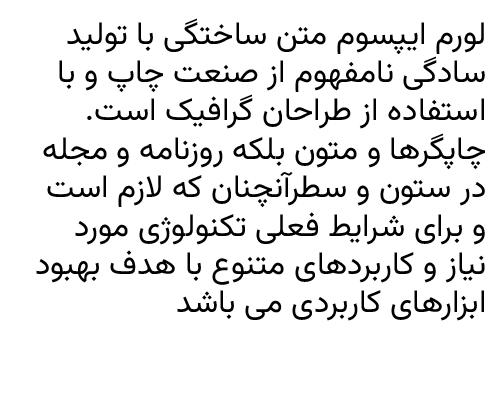

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



--- Extracted Text ---
لورم ایپسوم متن ساختگی با تولید سادگی نامفهوم از صنعت چاپ 9 با استفاده از طراحان گرافیک است . چاپگرها و متون بلکه روزنامه 9 مجله در ستون 9 سطرآنچنان که لازم اللت و براى شرايط فعلی تکنولوژی  مورد نياز وكاربردهاى متنوع با هدف بهبود ابزارهای کاربردی مى باشد

OCR processing time: 25.54 seconds


In [18]:

from google.colab import files
from PIL import Image
from IPython.display import display
import os

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

# Display the uploaded image
image = Image.open(image_path)
display(image)

# Extract text from the image
start_time = time.time()
results = reader.readtext(image_path, detail=0, paragraph=True)
ocr_time = time.time() - start_time

extracted_text = "\n".join(results)

print("\n--- Extracted Text ---")
print(extracted_text)

print(f"\nOCR processing time: {ocr_time:.2f} seconds")


In [19]:

import torch
import time
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "facebook/nllb-200-distilled-600M"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Translation device:", device)
print("Loading translation model...")

start_time = time.time()

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
translator = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
translator = translator.to(device)
translator.eval()

print(f"Translation model loaded in {time.time() - start_time:.1f} seconds.")


Translation device: cpu
Loading translation model...


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Translation model loaded in 15.4 seconds.


In [20]:

def translate_farsi_to_english(text, max_new_tokens=256):
    if not text or not text.strip():
        return ""

    tokenizer.src_lang = "pes_Arab"

    inputs = tokenizer(
        text.strip(),
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.inference_mode():
        translated_tokens = translator.generate(
            **inputs,
            forced_bos_token_id=tokenizer.convert_tokens_to_ids("eng_Latn"),
            max_new_tokens=max_new_tokens,
            num_beams=4
        )

    translation = tokenizer.batch_decode(
        translated_tokens,
        skip_special_tokens=True
    )[0]

    return translation


# Test with a sample Persian sentence
sample_farsi = "سلام، حال شما چطور است؟"

english_translation = translate_farsi_to_english(sample_farsi)

print("Persian:", sample_farsi)
print("English:", english_translation)


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Persian: سلام، حال شما چطور است؟
English: Hi, how are you?


In [23]:

def process_farsi_image(image_path):
    # 1. Extract Persian text from the image
    ocr_results = reader.readtext(
        image_path,
        detail=0,
        paragraph=True
    )

    extracted_text = "\n".join(ocr_results)

    # 2. Translate the extracted text
    translated_text = translate_farsi_to_english(extracted_text)

    return {
        "extracted_text": extracted_text,
        "translated_text": translated_text
    }


# Test using the image you uploaded in Step 4
result = process_farsi_image(image_path)

print("=== FARSI TEXT ===")
print(result["extracted_text"])

print("\n=== ENGLISH TRANSLATION ===")
print(result["translated_text"])


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


=== FARSI TEXT ===
لورم ایپسوم متن ساختگی با تولید سادگی نامفهوم از صنعت چاپ 9 با استفاده از طراحان گرافیک است . چاپگرها و متون بلکه روزنامه 9 مجله در ستون 9 سطرآنچنان که لازم اللت و براى شرايط فعلی تکنولوژی  مورد نياز وكاربردهاى متنوع با هدف بهبود ابزارهای کاربردی مى باشد

=== ENGLISH TRANSLATION ===
Lorem Epsom is a synthetic text with the unfathomable simplicity of the printing industry using graphic designers, printers and text, but newspaper 9 magazine in column 9 as necessary and for the current technological conditions required a variety of applications aimed at improving functional tools.


In [22]:

def translate_farsi_to_english(text, max_new_tokens=128):
    if not text or not text.strip():
        return ""

    tokenizer.src_lang = "pes_Arab"

    inputs = tokenizer(
        text.strip(),
        return_tensors="pt",
        truncation=True,
        max_length=512
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    target_id = tokenizer.convert_tokens_to_ids("eng_Latn")

    with torch.inference_mode():
        output = translator.generate(
            **inputs,
            forced_bos_token_id=target_id,
            max_new_tokens=max_new_tokens,
            num_beams=4,
            do_sample=False
        )

    return tokenizer.batch_decode(
        output,
        skip_special_tokens=True
    )[0]


# Test with a simple, known Persian sentence
test_text = "سلام، حال شما چطور است؟"
print("Input:", test_text)
print("Translation:", translate_farsi_to_english(test_text))


Input: سلام، حال شما چطور است؟


[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Translation: Hi, how are you?


In [37]:

test_text = "سلام، حال شما چطور است؟"

print("Input Persian:", test_text)
print("Output English:", translate_farsi_to_english(test_text))


Input Persian: سلام، حال شما چطور است؟


[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Output English: Hi, how are you?


In [25]:

print("OCR output:")
print(repr(result["extracted_text"]))


OCR output:
'لورم ایپسوم متن ساختگی با تولید سادگی نامفهوم از صنعت چاپ 9 با استفاده از طراحان گرافیک است . چاپگرها و متون بلکه روزنامه 9 مجله در ستون 9 سطرآنچنان که لازم اللت و براى شرايط فعلی تکنولوژی  مورد نياز وكاربردهاى متنوع با هدف بهبود ابزارهای کاربردی مى باشد'


In [26]:

real_persian = "سلام، من می‌خواهم زبان انگلیسی یاد بگیرم."

translation = translate_farsi_to_english(real_persian)

print("Persian:", real_persian)
print("English:", translation)


[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Persian: سلام، من می‌خواهم زبان انگلیسی یاد بگیرم.
English: Hi, I want to learn English.


In [27]:

def process_farsi_image(image_path):
    # Step 1: Extract Persian text from the image
    ocr_results = reader.readtext(
        image_path,
        detail=0,
        paragraph=True
    )

    extracted_text = "\n".join(ocr_results).strip()

    # Step 2: Translate extracted text into English
    if extracted_text:
        translated_text = translate_farsi_to_english(extracted_text)
    else:
        translated_text = "No readable text found in the image."

    # Step 3: Return both results
    return {
        "extracted_text": extracted_text,
        "translated_text": translated_text
    }


print("FarsiLens AI processing function is ready!")


FarsiLens AI processing function is ready!


In [28]:

result = process_farsi_image(image_path)

print("========== FARSI TEXT ==========")
print(result["extracted_text"])

print("\n========== ENGLISH TRANSLATION ==========")
print(result["translated_text"])


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


========== FARSI TEXT ==========
لورم ایپسوم متن ساختگی با تولید سادگی نامفهوم از صنعت چاپ 9 با استفاده از طراحان گرافیک است . چاپگرها و متون بلکه روزنامه 9 مجله در ستون 9 سطرآنچنان که لازم اللت و براى شرايط فعلی تکنولوژی  مورد نياز وكاربردهاى متنوع با هدف بهبود ابزارهای کاربردی مى باشد

========== ENGLISH TRANSLATION ==========
Lorem Epsom is a synthetic text with the unfathomable simplicity of the printing industry using graphic designers, printers and text, but newspaper 9 magazine in column 9 as necessary and for the current technological conditions required a variety of applications aimed at improving functional tools.


In [29]:
%pip -q install gradio

In [39]:
import gradio as gr

def run_farsilens(image_path):
    if image_path is None:
        return "Please upload an image.", ""

    try:
        result = process_farsi_image(image_path)

        farsi_text = result["extracted_text"]
        english_text = result["translated_text"]

        return farsi_text, english_text

    except Exception as e:
        return f"Error processing image: {e}", ""


demo = gr.Interface(
    fn=run_farsilens,
    inputs=gr.Image(type="filepath", label="Upload a Persian image"),
    outputs=[
        gr.Textbox(label="Extracted Persian Text", lines=8),
        gr.Textbox(label="English Translation", lines=8)
    ],
    title="FarsiLens AI",
    description="Upload an image containing Persian text to extract and translate it into English.",
    examples=None
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://49d4b6635891d57bc6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [31]:
print("OCR TEXT:")
print(ocr_text)

OCR TEXT:


NameError: name 'ocr_text' is not defined

In [32]:
extracted_text = " ".join(reader.readtext(
    image_path,
    detail=0,
    paragraph=True
))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [33]:
import torch

use_gpu = torch.cuda.is_available()
print("GPU available:", use_gpu)


GPU available: False


In [34]:
reader = easyocr.Reader(['fa', 'en'], gpu=use_gpu)

In [35]:
import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU — this is okay.")

GPU available: False
Running on CPU — this is okay.


In [36]:
results = reader.readtext(
    image_path,
    detail=0,
    paragraph=True
)

extracted_text = " ".join(results)

print("OCR TEXT:")
print(extracted_text)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


OCR TEXT:
لورم ایپسوم متن ساختگی با تولید سادگی نامفهوم از صنعت چاپ 9 با استفاده از طراحان گرافیک است . چاپگرها و متون بلکه روزنامه 9 مجله در ستون 9 سطرآنچنان که لازم اللت و براى شرايط فعلی تکنولوژی  مورد نياز وكاربردهاى متنوع با هدف بهبود ابزارهای کاربردی مى باشد


In [38]:
translation = translate_farsi_to_english(extracted_text)

print("OCR text:")
print(extracted_text)

print("\nEnglish translation:")
print(translation)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


OCR text:
لورم ایپسوم متن ساختگی با تولید سادگی نامفهوم از صنعت چاپ 9 با استفاده از طراحان گرافیک است . چاپگرها و متون بلکه روزنامه 9 مجله در ستون 9 سطرآنچنان که لازم اللت و براى شرايط فعلی تکنولوژی  مورد نياز وكاربردهاى متنوع با هدف بهبود ابزارهای کاربردی مى باشد

English translation:
Lorem Epsom is a synthetic text with the unfathomable simplicity of the printing industry using graphic designers, printers and text, but newspaper 9 magazine in column 9 as necessary and for the current technological conditions required a variety of applications aimed at improving functional tools.
